# LoRA rank: is the adapter too small?

Every adapter so far used mlx-lm's default LoRA rank, 8 (2.9M trainable parameters, 0.59% of the model). Learning rate and context barely moved the ~3.4 validation floor, and the data curve says more data still helps. One piece left unchecked is the adapter's own size. Parameters grow linearly with the rank (r x (d_in + d_out) per layer), so ranks 4, 8, 16 and 32 double the adapter at each step.

LoRA adds `scale * B @ A @ x`. With mlx-lm's fixed scale (20), a larger rank also makes each update to the weights larger, so a rank effect could really be a step-size effect. Two families separate the two:

- **fixed scale** (20 for every rank): "what happens if I only raise the rank in mlx-lm";
- **scaled** (scale = alpha / r with alpha = 160, the convention of the original LoRA paper): the same update size for every rank, so only capacity changes. Rank 8 is the same run in both (160 / 8 = 20).

Everything else is the published recipe (16 layers, lr 1e-5, effective batch 4, dropout 0), trained to 3,500 steps and measured every 200 steps on the full validation set (6 turns of context). Runs on the NAS GPU (RTX 3080, mlx-cuda, `--grad-accum 2`), so all runs come from the same machine.


## Prediction (written before running)

Seeing the earlier results, where adding more data kept lowering the floor, my theory is that the problem won't be the adapter, it will be the data. So I think a more powerful adapter won't improve, but we can't rule it out, and that's why we run the check.

If the adapter limits anything, a larger rank should improve the best validation loss by more than the noise we've seen (~0.02; ideally 0.05, to be checked with Seeds). An improvement wouldn't contradict the data curve: adapter size and data could both be limiting, and we'd be moving one lever instead of both. Parameters double with each rank step (4, 8, 16, 32). If doubling the adapter makes it reach its minimum earlier (rank 8: step 2,500) without a lower minimum, it is only memorizing faster, and the limit is the data.

With the fixed scale, a larger rank also takes larger steps, so an earlier minimum there could be step size and not capacity. If only the fixed-scale family improves, it was the step size; if both improve, it's capacity.

In [1]:
import json, os, re, subprocess
from pathlib import Path
os.environ["HF_HUB_DISABLE_PROGRESS_BARS"] = "1"
ROOT = Path("..").resolve()
R = ROOT / "experiments" / "results"
PY = os.environ.get("TLM_PY", "uv run python")              # NAS: TLM_PY=/opt/venv/bin/python
TRAIN_EXTRA = os.environ.get("TLM_TRAIN_EXTRA", "")         # NAS: TLM_TRAIN_EXTRA="--grad-accum 2"
RANKS = [4, 8, 16, 32]
ALPHA = 160  # scaled family: scale = ALPHA / rank, so rank 8 keeps scale 20

def run_name(r, family):
    return f"rank{r}" if family == "fixed" or r == 8 else f"rank{r}_a{ALPHA}"

RUNS = [(r, "fixed", 20.0) for r in RANKS] + [(r, "scaled", ALPHA / r) for r in RANKS if r != 8]

def run(cmd):
    """Run a command from the repo root, show its output here, and stop the notebook if it fails."""
    print("$", cmd, flush=True)
    p = subprocess.Popen(cmd, shell=True, cwd=ROOT, stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True)
    for line in p.stdout:
        if "Fetching" not in line:
            print(line, end="", flush=True)
    if p.wait() != 0:
        raise RuntimeError(f"failed ({p.returncode}): {cmd}")

## Train and measure each run (validation every 200 steps, 6 turns of context)

In [2]:
for r, family, scale in RUNS:
    name = run_name(r, family)
    if not (ROOT / "adapters" / name / "adapters.safetensors").exists():
        run(f"{PY} scripts/train.py --name {name} --data data/dataset/session --rank {r} --scale {scale} --iters 3500 {TRAIN_EXTRA}")
    run(f"{PY} scripts/eval_checkpoints.py adapters/{name} --data data/dataset/session/valid.jsonl --steps 300:3500:200 --out experiments/results/checkpoints_{name}.json")

$ /opt/venv/bin/python scripts/eval_checkpoints.py adapters/rank4 --data data/dataset/session/valid.jsonl --steps 300:3500:200 --out experiments/results/checkpoints_rank4.json
step   300: loss 3.579 (cached)
step   500: loss 3.539 (cached)
step   700: loss 3.512 (cached)
step   900: loss 3.478 (cached)
step  1100: loss 3.467 (cached)
step  1300: loss 3.497 (cached)
step  1500: loss 3.456 (cached)
step  1700: loss 3.452 (cached)
step  1900: loss 3.449 (cached)
step  2100: loss 3.450 (cached)
step  2300: loss 3.428 (cached)
step  2500: loss 3.426 (cached)
step  2700: loss 3.422 (cached)
step  2900: loss 3.447 (cached)
step  3100: loss 3.438 (cached)
step  3300: loss 3.435 (cached)
step  3500: loss 3.438 (cached)
best: step 2700, loss 3.422
$ /opt/venv/bin/python scripts/eval_checkpoints.py adapters/rank8 --data data/dataset/session/valid.jsonl --steps 300:3500:200 --out experiments/results/checkpoints_rank8.json
step   300: loss 3.557
step   500: loss 3.512
step   700: loss 3.485
step   

## Summary

family  rank  scale  params M best step best valid    1-7 tok   8-15 tok    16+ tok
fixed      4   20.0      1.47      2700      3.422      2.968      3.271      3.524
fixed      8   20.0      2.93      2700      3.408      2.949      3.253      3.512
fixed     16   20.0      5.87      2700      3.399      2.930      3.251      3.502
fixed     32   20.0     11.73      1100      3.406      3.001      3.282      3.493
scaled     4   40.0      1.47      2700      3.412      2.950      3.252      3.517
scaled     8   20.0      2.93      2700      3.408      2.949      3.253      3.512
scaled    16   10.0      5.87      2700      3.398      2.949      3.248      3.499
scaled    32    5.0     11.73      2500      3.399      2.958      3.262      3.495


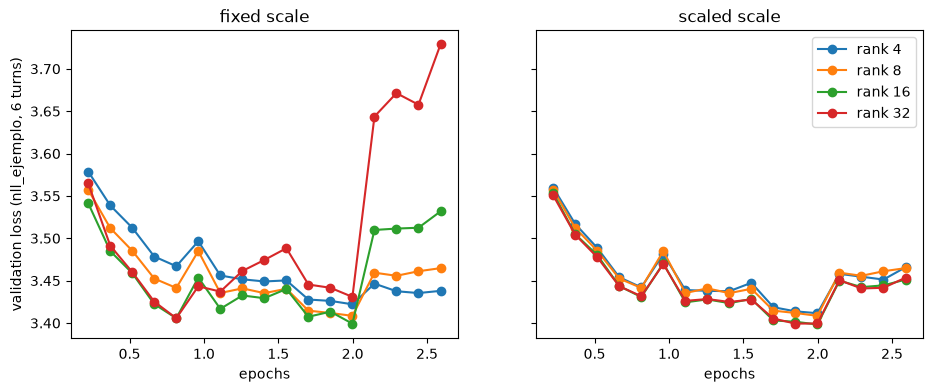

In [3]:
import numpy as np
import matplotlib.pyplot as plt

def trainable(name):
    log = (ROOT / f"adapters_{name}.log").read_text(errors="ignore")
    m = re.search(r"Trainable parameters: ([0-9.]+)% \(([0-9.]+)M", log)
    return float(m.group(2)) if m else float("nan")

BINS = [(1, 7), (8, 15), (16, 10**9)]
LABELS = ["1-7 tok", "8-15 tok", "16+ tok"]

def by_length(per_example):
    """Loss per reply token inside each reply-length bin (n = reply tokens)."""
    out = []
    for a, b in BINS:
        rows = [x for x in per_example if a <= x[1] <= b]
        out.append(sum(x[0] for x in rows) / sum(x[1] for x in rows))
    return out

curves = {}
print(f"{'family':<7} {'rank':>4} {'scale':>6} {'params M':>9} {'best step':>9} {'best valid':>10}  " + "  ".join(f"{l:>9}" for l in LABELS))
for family in ["fixed", "scaled"]:
    for r in RANKS:
        name = run_name(r, family)
        scale = 20.0 if family == "fixed" else ALPHA / r
        d = json.load(open(R / f"checkpoints_{name}.json"))
        v = {int(k): x for k, x in d["valid"].items()}
        best = min(v, key=v.get)
        curves[(family, r)] = v
        lens = by_length(d["per_example"][str(best)])
        print(f"{family:<7} {r:>4} {scale:>6.1f} {trainable(name):>9.2f} {best:>9} {v[best]:>10.3f}  " + "  ".join(f"{x:>9.3f}" for x in lens))

fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for ax, family in zip(axes, ["fixed", "scaled"]):
    for r in RANKS:
        v = curves[(family, r)]
        ax.plot([s * 4 / 5404 for s in sorted(v)], [v[s] for s in sorted(v)], marker="o", label=f"rank {r}")
    ax.set_title(f"{family} scale"); ax.set_xlabel("epochs")
axes[0].set_ylabel("validation loss (nll_ejemplo, 6 turns)"); axes[1].legend()
plt.show()

## Conclusion

| Rank | Fixed scale: best valid (step) | Scaled 160/r: best valid (step) | Replies of 16+ tokens (fixed / scaled) |
|---|---|---|---|
| 4 | 3.422 (2,700) | 3.412 (2,700) | 3.524 / 3.517 |
| 8 | 3.408 (2,700) | same run | 3.512 |
| 16 | 3.399 (2,700) | 3.398 (2,700) | 3.502 / 3.499 |
| 32 | 3.406 (**1,100**) | 3.399 (2,500) | 3.493 / 3.495 |

**The adapter is not the limit, as predicted.** Going from 1.5M to 11.7M trainable parameters (8 times more) moves the best validation loss by at most 0.024 in total, below the 0.02 to 0.05 per doubling set as the threshold. Rank 16 and 32 are marginally below rank 8 (~0.01), within the noise we've seen.

**The earlier minimum of rank 32 was step size, not capacity.** With the fixed scale, rank 32 reaches its minimum at step 1,100 without a lower value, which is what the prediction called "only memorizing faster". The scaled family is the control: with the update size held constant, rank 32 goes back to a minimum at step 2,500 like the others. The early minimum came from the larger effective updates of a higher rank at a fixed scale, not from the extra capacity.

**Where there is a small, consistent effect: long replies.** On replies of 16 tokens or more, the loss goes down a little with the rank in both families (3.524 to 3.493). That's where Length.ipynb places the part that is specifically mine, but 0.03 is small.

**Put together with Baselines.ipynb**, where the same recipe on Qwen2.5-1.5B reaches 3.150 against 3.418 for the 0.5B: the limit is not the adapter but the base model and the data. A bigger adapter on the same small model adds almost nothing; a bigger base model moves the loss several times more than doubling the data did.